<a href="https://colab.research.google.com/github/toddbalwinski/ds2002-midterm-project/blob/main/2026-10-30%20%E2%80%94%20Midterm%20Progress%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

In [20]:
#Loading in project data to notebook

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests
from pathlib import Path
from IPython.display import display

def find_data_dir():
    for folder in (Path("data"), Path("../data"), Path("/content/data"), Path("/content"), Path(".")):
        if (folder / "walmart_transactions.csv").exists():
            return folder
    raise FileNotFoundError("Put walmart_transactions.csv and store_locations.csv in a data/ folder next to this notebook")

DATA_DIR = find_data_dir()
raw_tx = pd.read_csv(DATA_DIR / "walmart_transactions.csv", dtype=str, keep_default_na=False)
raw_stores = pd.read_csv(DATA_DIR / "store_locations.csv", dtype=str, keep_default_na=False)
print("raw transactions:", len(raw_tx), "| raw store rows:", len(raw_stores))

MISSING = {"", "NULL", "N/A", "NA", "NAN", "NONE"}

def std_store_id(s):
    return (s.astype(str).str.strip().str.upper().str.replace("_", "-", regex=False)
             .str.replace(r"^FL-?(\d+)$", r"FL-\1", regex=True))

CATEGORY_MAP = {"Breakfast Foods": "Breakfast", "Emergency Supplies": "Emergency", "Alcoholic Beverages": "Alcohol",
                "Games & Entertainment": "Entertainment", "Groceries": "Grocery", "Household Essentials": "Household",
                "Health & Wellness": "Health", "Baby Products": "Baby"}

SKU_GROUPS = {
    "Strawberry Pop-Tarts": ["PT-12", "SKU#459812", "POPTART-STRAW", "PT_STRAWBERRY"],
    "Bottled Water 24-Pack": ["WTR-24", "WATER24PK", "WTR_24PK"],
    "AA Batteries 4-Pack": ["BATT-100", "BAT-AA4", "BATT_AA_4PK"],
    "LED Flashlight": ["FLASH-01", "LED-FLASH"],
    "Light Beer 24-Pack": ["BEER-24", "LTBEER24"],
    "Monopoly Board Game": ["BG-MONO", "MONOPOLY-01", "GAME-MONO"],
    "Playing Cards": ["CARDS-01", "PLAYCARD-STD"],
    "Streaming Device": ["STREAM-01", "ROKU-STD"],
    "Canned Soup": ["SOUP-CAN", "CNSOUP-01"],
    "White Bread": ["BREAD-WH", "WHITEBREAD"],
    "Peanut Butter 16oz": ["PB-16", "PNUTBTR-16"],
    "Emergency Candles": ["CNDL-EM", "CANDLE-EMRG"],
    "First Aid Kit": ["FAID-01", "FIRSTAID-KIT"],
    "Portable Phone Charger": ["CHRG-PORT", "PORTCHARGER"],
    "Chips Variety Pack": ["CHIPS-VP", "CHIPVARIETY"],
    "Paper Towels": ["PTOWEL-6", "PAPERTOWEL6"],
    "Toilet Paper 12-Roll": ["TP-12", "TOILETPAPER12"],
    "Baby Diapers Size 3": ["DIAP-S3", "DIAPERS-3"],
    "Baby Formula": ["BFORM-01", "BABYFORMULA"],
    "Heavy Duty Tarp": ["TARP-HD", "HDTARP-01"],
}
sku_mapping = pd.DataFrame([(s, fam) for fam, skus in SKU_GROUPS.items() for s in skus],
                           columns=["sku", "product_family"])
assert sku_mapping["sku"].is_unique

TIMESTAMP_FORMATS = ["%Y-%m-%d %H:%M:%S", "%Y-%m-%dT%H:%M:%S", "%m/%d/%Y %H:%M",
                     "%m-%d-%Y %H:%M:%S", "%d-%b-%Y %H:%M"]

def parse_timestamps(s):
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for fmt in TIMESTAMP_FORMATS:
        todo = out.isna() & s.notna()
        out[todo] = pd.to_datetime(s[todo], format=fmt, errors="coerce")
    assert (out.isna() & s.notna()).sum() == 0, "a timestamp format was not handled"
    return out

tx = raw_tx.apply(lambda c: c.str.strip()).copy()
tx = tx.mask(tx.apply(lambda c: c.str.upper().isin(MISSING)))
n0 = len(tx)
tx = tx.drop_duplicates()
print(f"duplicates removed: {n0 - len(tx)}  ({n0} -> {len(tx)})")
assert tx["transaction_id"].is_unique

tx["store_id"] = std_store_id(tx["store_id"])
tx["timestamp"] = parse_timestamps(tx["timestamp"])
tx["date"] = tx["timestamp"].dt.normalize()
tx["sku"] = tx["sku"].str.upper()
tx = tx.merge(sku_mapping, on="sku", how="left", validate="many_to_one")
tx["category"] = tx["category"].str.title().replace(CATEGORY_MAP)
tx["unit_price"] = pd.to_numeric(tx["unit_price"].str.replace("$", "", regex=False))
tx["quantity"] = pd.to_numeric(tx["quantity"]).astype(int)
tx["gross_units"] = tx["quantity"].clip(lower=0)

stores = raw_stores.copy()
stores["store_id"] = std_store_id(stores["store_id"])
stores = stores.drop_duplicates(subset="store_id")
stores["latitude"] = pd.to_numeric(stores["latitude"], errors="coerce")
stores["longitude"] = pd.to_numeric(stores["longitude"], errors="coerce")

assert tx["product_family"].notna().all(), "unmapped SKU"
assert tx["category"].nunique() == 10
assert set(tx["store_id"]) == set(stores["store_id"]) and len(stores) == 12
sales = tx[tx["date"].notna()].copy()                          # day-level analysis needs a date
assert (sales["date"].dt.month == 9).all() and sales["date"].nunique() == 30
print(f"missing timestamps (kept for SKU totals, excluded from daily analysis): {tx['date'].isna().sum()}")
print(f"analysis rows: {len(sales)} | stores: {sales['store_id'].nunique()} | categories: {sales['category'].nunique()} "
      f"| SKU codes: {tx['sku'].nunique()} -> products: {tx['product_family'].nunique()}")

LANDFALL = pd.Timestamp("2024-09-26")                          # Helene landfall ~11:10 PM EDT, Sept 26, 2024
BASELINE = (pd.Timestamp("2024-09-01"), pd.Timestamp("2024-09-15"))
SURGE = (pd.Timestamp("2024-09-19"), pd.Timestamp("2024-09-25"))

raw transactions: 25562 | raw store rows: 14
duplicates removed: 30  (25562 -> 25532)
missing timestamps (kept for SKU totals, excluded from daily analysis): 884
analysis rows: 24648 | stores: 12 | categories: 10 | SKU codes: 45 -> products: 20


### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [15]:
# TODO: the numbers
def window_avg(df, window, by=None):
    days = (window[1] - window[0]).days + 1
    sub = df[df["date"].between(*window)]
    return (sub.groupby(by)["gross_units"].sum() if by else sub["gross_units"].sum()) / days

q1 = pd.DataFrame({"baseline_units_per_day": window_avg(sales, BASELINE, "category"),
                   "surge_units_per_day": window_avg(sales, SURGE, "category")})
q1["multiple"] = q1["surge_units_per_day"] / q1["baseline_units_per_day"]
q1["pct_increase"] = (q1["multiple"] - 1) * 100
q1["abs_increase_per_day"] = q1["surge_units_per_day"] - q1["baseline_units_per_day"]
q1 = q1.sort_values("pct_increase", ascending=False)
top5 = list(q1.index[:5])

tot_base, tot_surge = window_avg(sales, BASELINE), window_avg(sales, SURGE)
print(f"Baseline window: {BASELINE[0]:%b %d} - {BASELINE[1]:%b %d}, 2024 (15 days of flat, pre-storm demand)")
print(f"Surge window:    {SURGE[0]:%b %d} - {SURGE[1]:%b %d}, 2024 (the 7 full days before landfall on Sep 26)")
print(f"All categories: baseline {tot_base:,.0f} units/day -> surge {tot_surge:,.0f} units/day = {tot_surge / tot_base:.2f}x\n")
display(q1.round(1))
print("Top 5 by relative increase:", top5)

Baseline window: Sep 01 - Sep 15, 2024 (15 days of flat, pre-storm demand)
Surge window:    Sep 19 - Sep 25, 2024 (the 7 full days before landfall on Sep 26)
All categories: baseline 1,103 units/day -> surge 2,712 units/day = 2.46x



,baseline_units_per_day,surge_units_per_day,multiple,pct_increase,abs_increase_per_day
category,,,,,
Breakfast,73.3,376.9,5.1,414.4,303.6
Emergency,354.1,1006.4,2.8,184.2,652.4
Electronics,70.3,175.9,2.5,150.3,105.6
Alcohol,61.5,138.9,2.3,125.7,77.3
Entertainment,101.6,228.6,2.2,125.0,127.0
Health,42.3,95.0,2.2,124.4,52.7
Household,85.1,176.3,2.1,107.1,91.2
Grocery,171.1,306.6,1.8,79.2,135.5
Baby,85.2,133.7,1.6,56.9,48.5


Top 5 by relative increase: ['Breakfast', 'Emergency', 'Electronics', 'Alcohol', 'Entertainment']


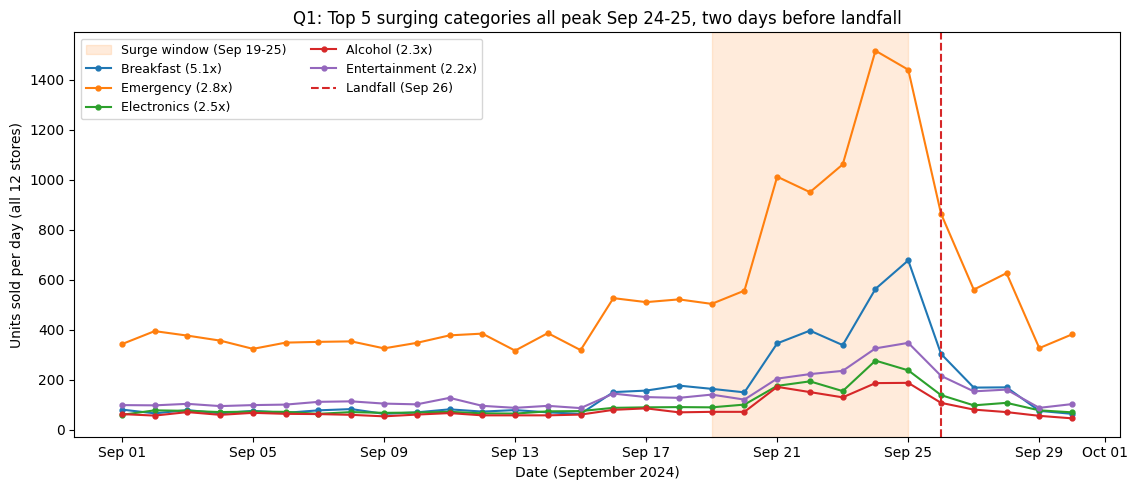

In [16]:
# TODO: the chart
cat_daily = sales.pivot_table(index="date", columns="category", values="gross_units", aggfunc="sum")

fig, ax = plt.subplots(figsize=(11.5, 5))
ax.axvspan(*SURGE, color="tab:orange", alpha=0.15, label="Surge window (Sep 19-25)")
for c in top5:
    ax.plot(cat_daily.index, cat_daily[c], marker="o", ms=3.5, label=f"{c} ({q1.loc[c, 'multiple']:.1f}x)")
ax.axvline(LANDFALL, color="tab:red", ls="--", label="Landfall (Sep 26)")
ax.set_title("Q1: Top 5 surging categories all peak Sep 24-25, two days before landfall")
ax.set_xlabel("Date (September 2024)")
ax.set_ylabel("Units sold per day (all 12 stores)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

**Q1 answer, in one sentence a manager could read:** Sales in the week before landfall ran ~2.5 times average with breakfast having the largest jump in percent of sales and emergency supplies having the largest unit jump in sales.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Distinct SKU codes in transactions: 45
Canonical products (families):      20
Largest consolidated family:        Strawberry Pop-Tarts (4 SKU codes: ['PT-12', 'SKU#459812', 'POPTART-STRAW', 'PT_STRAWBERRY'])

PASS: unit totals identical before and after consolidation: 49584 units



,baseline/day,surge/day,peak (Sep 25),peak multiple
POPTART-STRAW,18.0,91.0,134,7.4
PT-12,20.4,103.3,240,11.8
PT_STRAWBERRY,18.1,92.4,165,9.1
SKU#459812,16.8,90.1,139,8.3
CONSOLIDATED,73.3,376.9,678,9.3


Surge-week rank: best single Pop-Tart SKU #3 of 45 SKU codes -> consolidated Pop-Tarts #1 of 20 products


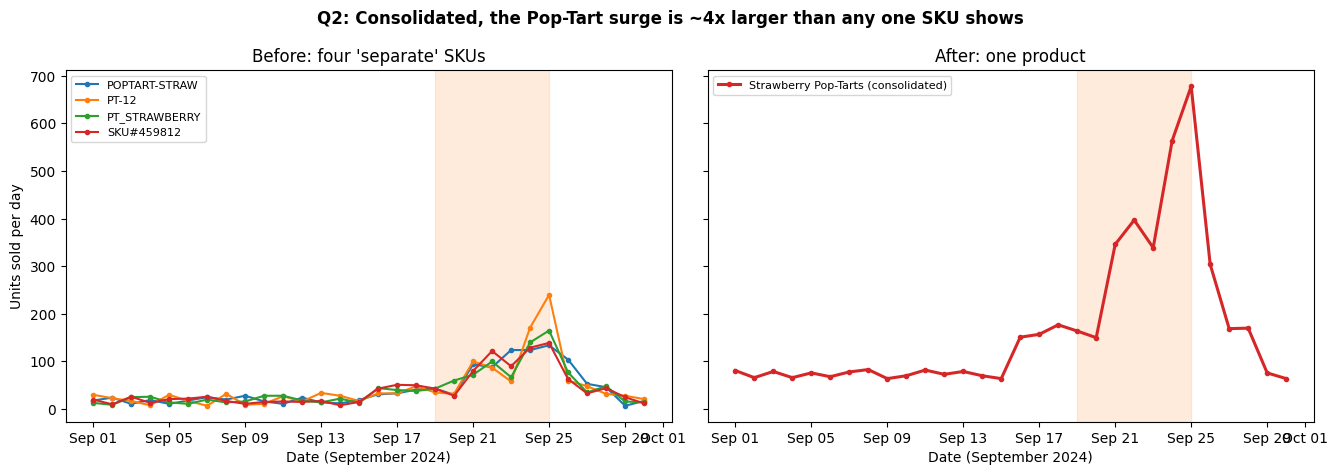

In [17]:
# TODO
fam_counts = sku_mapping["product_family"].value_counts()
print(f"Distinct SKU codes in transactions: {tx['sku'].nunique()}")
print(f"Canonical products (families):      {tx['product_family'].nunique()}")
print(f"Largest consolidated family:        {fam_counts.idxmax()} ({fam_counts.max()} SKU codes: {SKU_GROUPS[fam_counts.idxmax()]})\n")

by_sku = tx.groupby("sku")["gross_units"].sum()
by_family = tx.groupby("product_family")["gross_units"].sum()
assert by_sku.sum() == by_family.sum() == tx["gross_units"].sum()
assert by_family["Strawberry Pop-Tarts"] == by_sku[SKU_GROUPS["Strawberry Pop-Tarts"]].sum()
print("PASS: unit totals identical before and after consolidation:", int(by_family.sum()), "units\n")

pt = sales[sales["product_family"] == "Strawberry Pop-Tarts"]
frag = pt.pivot_table(index="date", columns="sku", values="gross_units", aggfunc="sum", fill_value=0)
cons = pt.groupby("date")["gross_units"].sum()
avg = lambda s, w: s.loc[w[0]:w[1]].mean()
q2 = pd.DataFrame({
    "baseline/day": [avg(frag[c], BASELINE) for c in frag] + [avg(cons, BASELINE)],
    "surge/day": [avg(frag[c], SURGE) for c in frag] + [avg(cons, SURGE)],
    "peak (Sep 25)": [frag.loc["2024-09-25", c] for c in frag] + [cons.loc["2024-09-25"]],
}, index=list(frag.columns) + ["CONSOLIDATED"])
q2["peak multiple"] = q2["peak (Sep 25)"] / q2["baseline/day"]
display(q2.round(1))

surge_rows = sales[sales["date"].between(*SURGE)]
rank_sku = surge_rows.groupby("sku")["gross_units"].sum().rank(ascending=False, method="min")
rank_fam = surge_rows.groupby("product_family")["gross_units"].sum().rank(ascending=False, method="min")
print(f"Surge-week rank: best single Pop-Tart SKU #{int(rank_sku[SKU_GROUPS['Strawberry Pop-Tarts']].min())} of {len(rank_sku)} "
      f"SKU codes -> consolidated Pop-Tarts #{int(rank_fam['Strawberry Pop-Tarts'])} of {len(rank_fam)} products")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), sharey=True)
for c in frag.columns:
    axes[0].plot(frag.index, frag[c], marker="o", ms=3, label=c)
axes[0].set_title("Before: four 'separate' SKUs")
axes[1].plot(cons.index, cons, color="tab:red", marker="o", ms=3, lw=2.2, label="Strawberry Pop-Tarts (consolidated)")
axes[1].set_title("After: one product")
for ax in axes:
    ax.axvspan(*SURGE, color="tab:orange", alpha=0.15)
    ax.set_xlabel("Date (September 2024)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.legend(fontsize=8)
axes[0].set_ylabel("Units sold per day")
plt.suptitle("Q2: Consolidated, the Pop-Tart surge is ~4x larger than any one SKU shows", fontweight="bold")
plt.tight_layout(); plt.show()

**Q2 answer:** We turned 45 SKU codes into 20 products. Our largest consoldated family was strawberry poptarts with 4 different codes. By consolodating the poptarts we could clearly see that they were the item that jumped up the most. We also passed our assertion that the unit totals did not change.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

Source: https://archive-api.open-meteo.com/v1/archive | store FL-239 (Orlando) | LIVE API data, 30 local days
Rows before join: 30 | after: 30 | units 3911 -> 3911 | nothing lost: True

Same-day Pearson r, computed over n = 30 days (small n: one storm, one month)


,wind_max_kmh,gust_max_kmh,precip_mm,pressure_min_hpa
gross_units,0.44,0.38,-0.26,-0.29
Alcohol,0.37,0.31,-0.08,-0.33
Baby,-0.12,-0.16,-0.26,0.17
Breakfast,0.43,0.38,-0.24,-0.34
Electronics,0.23,0.18,-0.17,-0.13
Emergency,0.49,0.43,-0.25,-0.35
Entertainment,0.39,0.33,-0.18,-0.20
Grocery,0.17,0.13,-0.30,0.02
Health,0.37,0.33,-0.21,-0.27
Household,0.35,0.28,-0.21,-0.22


Strongest lag for each indicator:


,weather,lag_days,r,n_days
15,gust_max_kmh,2,0.76,28
21,precip_mm,-1,-0.44,29
33,pressure_min_hpa,2,-0.70,28
6,wind_max_kmh,2,0.78,28


Sales peak: Sep 24 | gust peak: Sep 26 | pressure low: Sep 26


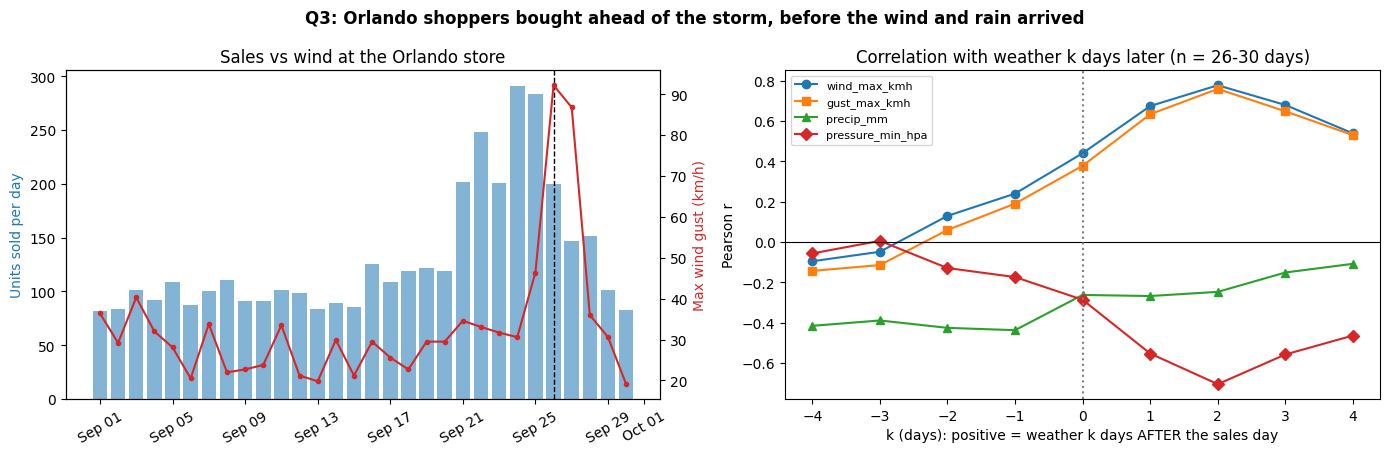

In [18]:
# TODO
WEATHER_URL = "https://archive-api.open-meteo.com/v1/archive"
RETRYABLE = {429, 500, 502, 503, 504}

def fetch_hourly_weather(lat, lon, start="2024-08-31", end="2024-10-01", attempts=3):
    params = {"latitude": lat, "longitude": lon, "start_date": start, "end_date": end,
              "hourly": "wind_speed_10m,wind_gusts_10m,precipitation,pressure_msl",
              "timezone": "GMT", "wind_speed_unit": "kmh"}
    for attempt in range(attempts):
        try:
            r = requests.get(WEATHER_URL, params=params, timeout=30)
            if r.status_code in RETRYABLE and attempt < attempts - 1:
                time.sleep(2 ** attempt); continue
            r.raise_for_status()
            payload = r.json()
            if "hourly" not in payload:
                raise ValueError(f"no hourly data in response: {str(payload)[:200]}")
            h = pd.DataFrame(payload["hourly"])
            h["time_utc"] = pd.to_datetime(h.pop("time"), format="%Y-%m-%dT%H:%M").dt.tz_localize("UTC")
            return h
        except requests.RequestException:
            if attempt == attempts - 1:
                raise
            time.sleep(2 ** attempt)

STORE = "FL-239"
st = stores.set_index("store_id").loc[STORE]
hourly = fetch_hourly_weather(st["latitude"], st["longitude"])

hourly["date"] = hourly["time_utc"].dt.tz_convert("America/New_York").dt.tz_localize(None).dt.normalize()
weather = (hourly.groupby("date")
           .agg(wind_max_kmh=("wind_speed_10m", "max"), gust_max_kmh=("wind_gusts_10m", "max"),
                precip_mm=("precipitation", "sum"), pressure_min_hpa=("pressure_msl", "min"),
                hours=("time_utc", "size"))
           .loc["2024-09-01":"2024-09-30"].reset_index())
assert len(weather) == 30 and (weather["hours"] == 24).all(), "incomplete local days"
weather["source"] = "Open-Meteo archive " + WEATHER_URL
print(f"Source: {WEATHER_URL} | store {STORE} ({st['city']}) | LIVE API data, {len(weather)} local days")

store_daily = (sales[sales["store_id"] == STORE]
               .pivot_table(index="date", columns="category", values="gross_units", aggfunc="sum", fill_value=0))
store_daily["gross_units"] = store_daily.sum(axis=1)
store_daily = store_daily.reset_index()

n_before = len(store_daily)
units_before = store_daily["gross_units"].sum()
sales_weather = store_daily.merge(weather, on="date", how="left", validate="one_to_one", indicator=True)
q3_join_rows_preserved = bool(len(sales_weather) == n_before
                              and (sales_weather["_merge"] == "both").all()
                              and sales_weather["gross_units"].sum() == units_before)
print(f"Rows before join: {n_before} | after: {len(sales_weather)} | units {units_before} -> {sales_weather['gross_units'].sum()} "
      f"| nothing lost: {q3_join_rows_preserved}")
assert q3_join_rows_preserved

WEATHER_COLS = ["wind_max_kmh", "gust_max_kmh", "precip_mm", "pressure_min_hpa"]
CATS = sorted(sales["category"].unique())
q3_corr = sales_weather[["gross_units"] + CATS + WEATHER_COLS].corr().loc[["gross_units"] + CATS, WEATHER_COLS]
q3_days = len(sales_weather)
print(f"\nSame-day Pearson r, computed over n = {q3_days} days (small n: one storm, one month)")
display(q3_corr.round(2))

lag_rows = []
sw = sales_weather.set_index("date")
for var in WEATHER_COLS:
    for k in range(-4, 5):
        pair = pd.concat([sw["gross_units"], sw[var].shift(-k)], axis=1).dropna()
        lag_rows.append({"weather": var, "lag_days": k, "r": pair.corr().iloc[0, 1], "n_days": len(pair)})
lag_df = pd.DataFrame(lag_rows)
best = lag_df.loc[lag_df.groupby("weather")["r"].apply(lambda s: s.abs().idxmax())]
print("Strongest lag for each indicator:")
display(best.round(2))
print(f"Sales peak: {sw['gross_units'].idxmax():%b %d} | gust peak: {sw['gust_max_kmh'].idxmax():%b %d} | "
      f"pressure low: {sw['pressure_min_hpa'].idxmin():%b %d}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax1 = axes[0]
ax1.bar(sw.index, sw["gross_units"], color="tab:blue", alpha=0.55, label=f"Units sold ({STORE} {st['city']})")
ax1.set_ylabel("Units sold per day", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(sw.index, sw["gust_max_kmh"], color="tab:red", marker="o", ms=3, label="Max wind gust (km/h)")
ax2.set_ylabel("Max wind gust (km/h)", color="tab:red")
ax1.axvline(LANDFALL, color="black", ls="--", lw=1)
ax1.set_title(f"Sales vs wind at the {st['city']} store")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %d")); ax1.tick_params(axis="x", rotation=30)
for var, style in zip(WEATHER_COLS, ["-o", "-s", "-^", "-D"]):
    sub = lag_df[lag_df["weather"] == var]
    axes[1].plot(sub["lag_days"], sub["r"], style, label=var)
axes[1].axhline(0, color="black", lw=0.8); axes[1].axvline(0, color="gray", ls=":")
axes[1].set_title(f"Correlation with weather k days later (n = {q3_days - 4}-{q3_days} days)")
axes[1].set_xlabel("k (days): positive = weather k days AFTER the sales day")
axes[1].set_ylabel("Pearson r"); axes[1].legend(fontsize=8)
plt.suptitle("Q3: Orlando shoppers bought ahead of the storm, about 2 days before the wind peaked", fontweight="bold")
plt.tight_layout(); plt.show()

**Q3 answer, with its caveat:** All of the rows were kept after the join with the data from the open meteo archive API connection. The correlation is computed over 30 days and we can see the that the sales peak before the units surge with lets us imply that people shop to prepare based on the forcast and not during a storm. The caveat is that this is one storm and one store and does not take any other factors that could have been at play into effect.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** Mostly complete, Todd is touching up the graph.

**Q5 (signal or artifact):** Also mostly complete with Todd touching up the graph

### Self-check

In [19]:
progress = {
    'q1_multiple': 2.46,            # TODO: a number
    'q1_baseline_window': '9/1/24 to 9/15/24',   # TODO: stated explicitly
    'q2_canonical_products': 20,  # TODO: a number
    'q3_join_rows_preserved': True, # TODO: True/False
    'q3_days_in_correlation': 30, # TODO: a number
    'charts_with_message_titles': 3,  # TODO: how many
    'notebook_runs_clean': True,   # TODO: True after Restart and Run All
    'repo_pushed': True,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 2.46
PASS - q1_baseline_window = 9/1/24 to 9/15/24
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 3
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

a) One thing that suprised us was that breakfast had the largest percent increase breakfast had the biggest percent increase and not emergency items. The emergency items units numbers surged a lot so we check the data from pre-surge to make sure that it was as high as it said. We also looked into the breakfast item data to make sure nothing was being overreported or was categorized wrong. b) The number that we are the least confident in is the 2 day lag correlation  because it rests on only 28 days from our one example that we looked into. Also moving our window by a day or dropping one day could change the numbers a lot. It is also strange that rain does nto follow the same pattern so not all weather measures are the same.